In [40]:
import numpy as np
import matplotlib.pyplot as plt

CAPA FISICA $\newline$
FUNCIONES A REALIZAR: ECUACIACION DIFERENCIAL, VERIFICACION DE LOS INVARIANTES
 

In [41]:

#VALORES INCIALES EJEMPLO
I_vect=[1.0, 2.0, 3.0]  # Moments of inertia
w_vect=[0.1, 0.2, 0.3]  # Angular velocities

#ECUACION DIFERENCIAL
def eq_diff(I_vect, w_vect):
    """
    Define the differential equation for the system.
    
    Parameters:
    I_vect (list): Moments of inertia [I1, I2, I3].
    w_vect (list): Angular velocities [w1, w2, w3].
    
    Returns:
    list: Derivatives of angular velocities [dw1/dt, dw2/dt, dw3/dt].
    """
    I1, I2, I3 = I_vect
    w1, w2, w3 = w_vect
    
    dw1_dt = ((I2 - I3) / I1) * w2 * w3
    dw2_dt = ((I3 - I1) / I2) * w3 * w1
    dw3_dt = ((I1 - I2) / I3) * w1 * w2
    
    return [dw1_dt, dw2_dt, dw3_dt]

#ECUACION DIFERENCIAL EJEMPLO
dw_vect = eq_diff(I_vect, w_vect)
print("Derivatives of angular velocities:")
for i, dw in enumerate(dw_vect, start=1):
    print(f"dw{i}/dt = {dw}")



Derivatives of angular velocities:
dw1/dt = -0.06
dw2/dt = 0.03
dw3/dt = -0.006666666666666667


In [ ]:
#CONSERVACION ENERGIA 
def cons_energia(I_vect, w_vect):
    I1, I2, I3 = I_vect
    w1, w2, w3 = w_vect
    
    T = 0.5 * (I1 * w1**2 + I2 * w2**2 + I3 * w3**2)
    
    return T

#CONSERVACION MOMENTO ANGULAR
def cons_angular(I_vect, w_vect):
    I1, I2, I3 = I_vect
    w1, w2, w3 = w_vect
    L_cuadrado = I1**2 * w1**2 + I2**2 * w2**2 + I3**2 * w3**2
    
    return L_cuadrado

CAPA NUMERICA $\newline$
FUNCIONES A REALIZAR: ESQUEMAS NUMERICOS (EULER, RK4, CN), CAUCHY, GAUSS, NEWTON, JACOBIANO, ERROR RICHARDSON, AUTOVALORES.



In [ ]:

#JACOBIANO
def jacobiano(F, I_vect, w_vect, eps=1e-8):
    """
    Calcula la matriz Jacobiana numéricamente dada la función de la EDO (F).
    Returns:
    list: Matriz Jacobiana como lista de listas.
    """
    n = len(w_vect)
    J = np.zeros((n, n), dtype=float)
    
    for j in range(n):
        # Creamos copias del vector de estado para perturbar solo la componente j
        w_plus = list(w_vect)
        w_minus = list(w_vect)
        
        w_plus[j] += eps
        w_minus[j] -= eps
        
        # Evaluamos la EDO en los puntos perturbados
        f_plus = np.asarray(F(I_vect, w_plus), dtype=float)
        f_minus = np.asarray(F(I_vect, w_minus), dtype=float)
        
        # Columna j del Jacobiano (derivada respecto a w_j)
        J[:, j] = (f_plus - f_minus) / (2.0 * eps)
        
    return J.tolist()

# EJEMPLO DE USO DEL JACOBIANO
J = jacobiano(eq_diff, I_vect, w_vect)
print("Jacobian matrix:")
for row in J:
    print(row)

Jacobian matrix:
[0.0, -0.29999999984209325, -0.19999999989472883]
[0.29999999984209325, 0.0, 0.09999999994736442]
[-0.06666666663157628, -0.03333333331578814, 0.0]


In [ ]:
#CALCULO DE RAICES: GAUSS Y NEWTON
#Eliminacion de Gauss
def gauss_elimination(A, b):
    """
    Resuelve el sistema lineal A * x = b mediante eliminación de Gauss 
    con pivoteo parcial.
    
    Returns:
    np.ndarray: Vector solución x.
    """
    # Copiamos como float para no modificar las variables originales
    A_mat = np.array(A, dtype=float)
    b_vec = np.array(b, dtype=float)
    n = len(b_vec)
    
    # 1. Fase de eliminación hacia adelante
    for i in range(n):
        # Pivoteo parcial: buscar el máximo en la columna i (desde la fila i hacia abajo)
        max_row = i + np.argmax(np.abs(A_mat[i:, i]))
        
        if abs(A_mat[max_row, i]) < 1e-14:
            raise ValueError("La matriz es singular o casi singular.")
            
        # Intercambiar filas si el máximo no está en la fila actual
        if max_row != i:
            A_mat[[i, max_row]] = A_mat[[max_row, i]]
            b_vec[[i, max_row]] = b_vec[[max_row, i]]
            
        # Hacer ceros debajo del pivote A_mat[i, i]
        for j in range(i + 1, n):
            factor = A_mat[j, i] / A_mat[i, i]
            A_mat[j, i:] -= factor * A_mat[i, i:]
            b_vec[j] -= factor * b_vec[i]
            
    # 2. Fase de sustitución hacia atrás
    x = np.zeros(n, dtype=float)
    for i in range(n - 1, -1, -1):
        suma = np.dot(A_mat[i, i + 1:], x[i + 1:])
        x[i] = (b_vec[i] - suma) / A_mat[i, i]
        
    return x

#Calculo de raices: Newton
# Método de Newton-Raphson para sistemas de ecuaciones no lineales G(x) = 0
def newton_raphson(G, JG, x0, tol=1e-10, max_iter=20):
    """
    Encuentra la raíz del sistema no lineal G(x) = 0.
    Returns:
    list: Vector solución x tal que G(x) ≈ 0.
    """
    x = x0[:]  # Copia de la semilla inicial
    
    for _ in range(max_iter):
        fx = G(x)
        
        # 1. Criterio de parada: si el máximo error (norma infinito) es menor que tol
        if max(abs(val) for val in fx) < tol:
            return x
            
        # 2. Evaluar el Jacobiano en el punto actual
        J = JG(x)
        
        # 3. Resolver el sistema lineal J * delta = fx usando tu función de Gauss
        delta = gauss_elimination(J, fx)
        
        # 4. Actualizar la estimación: x_nuevo = x - delta
        x = [x[i] - delta[i] for i in range(len(x))]
        
    raise RuntimeError("Newton-Raphson no convergió dentro de max_iter.")


solucion euler:[0.0994, 0.2003, 0.29993333333333333]
solucion rk4:[0.09939961756635438, 0.20029906646727663, 0.29993348372171746]
solucion cn:[np.float64(0.09939961801599441), np.float64(0.20029906636865735), np.float64(0.29993348391552394)]
Diferencia en energía cinética entre el momento inicial y final: -1.2429490086285355e-05
Diferencia en momento angular entre el momento inicial y final: -3.016225437690867e-05


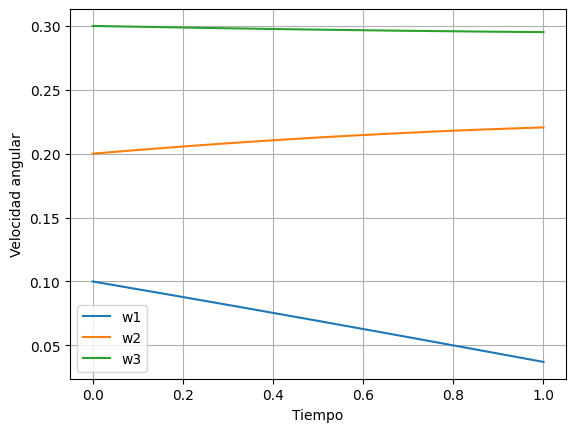

In [ ]:
#ESQUEMAS NUMERICOS (EULER, RK4, CN) y CAUCHY
#F=eq_diff, U=w_vect, I=I_vect, h=0.01
def Euler(F, U, I, h):
    der = F(I, U)
    U_nuevo = []

    for i in range(len(U)):
        U_nuevo.append(U[i] + h * der[i])

    return U_nuevo


def RK4(F, U, I, h):
    k1 = F(I, U)
    U_k2 = [U[i] + 0.5 * h * k1[i] for i in range(len(U))]
    k2 = F(I, U_k2)
    
    U_k3 = [U[i] + 0.5 * h * k2[i] for i in range(len(U))]
    k3 = F(I, U_k3)
    
    U_k4 = [U[i] + h * k3[i] for i in range(len(U))]
    k4 = F(I, U_k4)
    
    U_nuevo = [U[i] + (h / 6) * (k1[i] + 2 * k2[i] + 2 * k3[i] + k4[i]) for i in range(len(U))]
    
    return U_nuevo

def Crank_Nicolson(F, JF, U, I, h, tol=1e-10, max_iter=20):
    F_n = F(I, U)
    n = len(U)
    
    # Semilla inicial x0: damos un paso rápido con Euler
    U_0 = Euler(F, U, I, h)
    
    # Función residuo G(U_next) = 0 de Crank-Nicolson
    def G(U_next):
        F_next = F(I, U_next)
        return [U_next[i] - U[i] - 0.5 * h * (F_n[i] + F_next[i]) for i in range(n)]
    
    # Jacobiano del residuo: Matriz Identidad - (h/2) * Jacobiano de F
    def JG(U_next):
        J_F = JF(F, I, U_next)
        return [[(1.0 if i == j else 0.0) - 0.5 * h * J_F[i][j] for j in range(n)] for i in range(n)]
        
    return newton_raphson(G, JG, U_0, tol, max_iter)

print("solucion euler:" + str(Euler(eq_diff, w_vect, I_vect, 0.01)))
print("solucion rk4:" + str(RK4(eq_diff, w_vect, I_vect, 0.01)))
print("solucion cn:" + str(Crank_Nicolson(eq_diff, jacobiano, w_vect, I_vect, 0.01)))

def integrate_cauchy(scheme, F, U0, I, t_array):
    """
    Integra un problema de Cauchy.
    Retorna:
    - U: Array con la solución en cada instante de tiempo.
    """
    # Determinamos el número de pasos de tiempo
    num_steps = len(t_array)
    
    # Preparamos el array para almacenar la solución
    # Verifica si U0 es un escalar o un vector (para sistemas de ecuaciones)
    if isinstance(U0, (int, float)):
        U = np.zeros(num_steps)
    else:
        U = np.zeros((num_steps, len(U0)))
        
    # Aplicamos la condición inicial
    U[0] = U0
    
    # Bucle de integración temporal
    for i in range(num_steps - 1):
        t = t_array[i]
        # Calculamos el tamaño del paso de tiempo actual (h)
        h = t_array[i+1] - t_array[i]
        
        # Invocamos el esquema temporal pasado como argumento
        U[i+1] = scheme(F, U[i], I, h)
        
    return U

#EJEMPLO CAUCHY (Y CONSERVACION DE ENERGIA Y MOMENTO ANGULAR)
U = integrate_cauchy(Euler, eq_diff, w_vect, I_vect, np.linspace(0, 1, 200))
t_cauchy = np.linspace(0, 1, 200)
E=[cons_energia(I_vect, U[i]) for i in range(len(U))]
L=[cons_angular(I_vect, U[i]) for i in range(len(U))]
print("Diferencia en energía cinética entre el momento inicial y final:", E[0]-E[-1])
print("Diferencia en momento angular entre el momento inicial y final:", L[0]-L[-1])
plt.plot(t_cauchy, U, label=['w1', 'w2', 'w3'])
plt.xlabel('Tiempo')
plt.ylabel('Velocidad angular')
plt.legend()
plt.grid()
plt.show()

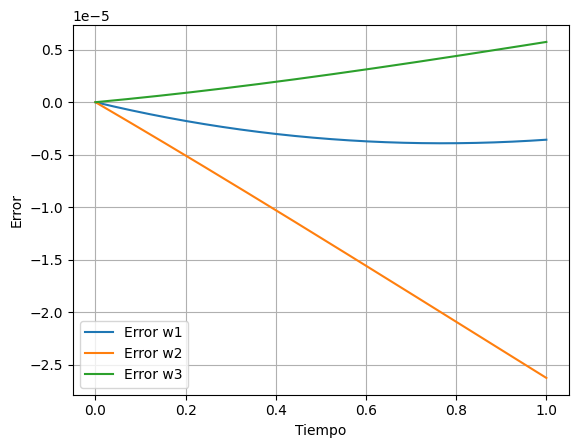

In [46]:
#RICHARDSON
def richardson_error(scheme, F, U0, I, t_array, q=None):
    """
    Retorna el error: Array con el vector de error estimado en cada instante de t_array.
    """
    N = len(t_array) - 1
    # Creamos la malla fina t2 con el doble de pasos (paso h/2) -> 2*N + 1 nodos
    t_fine = np.linspace(t_array[0], t_array[-1], 2 * N + 1)
    
    # Integramos el problema de Cauchy en ambas mallas
    U_coarse = integrate_cauchy(scheme, F, U0,I_vect, t_array)
    U_fine = integrate_cauchy(scheme, F, U0, I_vect, t_fine)
    
    # Los instantes de t_array coinciden exactamente con los índices pares de t_fine (0, 2, 4...)
    diff = U_fine[0::2] - U_coarse
    
    # Aplicamos el factor de corrección de Richardson si se especifica el orden q
    if q is not None:
        error = diff / (1.0 - (0.5)**q)
    else:
        error = diff
        
    return error

#EJEMPLO RICHARDSON
t_array = np.linspace(0, 1, 200)  # 201 nodos, paso h = 0.025
error_richardson = richardson_error(Euler, eq_diff, w_vect,I_vect, t_array, q=4)
plt.plot(t_array, error_richardson, label=['Error w1', 'Error w2', 'Error w3'])
plt.xlabel('Tiempo')
plt.ylabel('Error')
plt.legend()
plt.grid()
plt.show()